# 05. Local z-score (3-sigma)

Each pixel compared with the mean and standard deviation of its window: |x − mean| / std. Normalises for local contrast, so it adapts to textured and smooth regions.

Method: `filters.py` (`METHOD_NAME = "local_zscore"`). Evaluation: `evaluate.py`, same rules for every experiment (README section 7): threshold from `good_cal` only, false alarms on unseen `good_test` strips and on hard negatives, recall on defect tiles. Per-tile scores and the cal/test split are saved to `results/local_zscore/`.

In [1]:
import sys, importlib

sys.path.insert(0, "../src/methods")
import filters as F    # all filters and methods
import evaluate as E   # shared evaluation (README section 7)
importlib.reload(F); importlib.reload(E)  # pick up edits without restarting the kernel

# ---- evaluation settings (same for every experiment) ----------------------
FABRIC = "02"           # fabric code = third part of the file name
METHOD_NAME = "local_zscore"  # results go to results/<METHOD_NAME>/
THR_K = 4.0             # threshold = median + THR_K x 1.4826 x MAD of good_cal scores
MIN_AREA = 4            # damage mask: drop spots smaller than this (px); keep <= 4
SCORE_K = 25            # tile score = mean of the SCORE_K highest values of the smoothed map
SCORE_SIGMA = 2.0       # smoothing before scoring (px)
NORMALIZE = True        # score = strongest spot / the tile's own typical level (removes strip-to-strip bias)
SETTINGS = dict(thr_k=THR_K, min_area=MIN_AREA, score_k=SCORE_K, score_sigma=SCORE_SIGMA,
                normalize=NORMALIZE)

# ---- method settings -------------------------------------------------------
STEPS = F.DEFAULT_STEPS
WIN = 31                  # window size (px)


def method(tile):
    return F.local_zscore(tile, STEPS, win=WIN)


fit = None

## Results for one fabric

In [2]:
res = E.evaluate(method, FABRIC, fit=fit, **SETTINGS)
assert res is not None, f"not enough tiles for fabric {FABRIC}"
S = E.summarize(res)
E.print_summary(res, S)
print("saved to", E.save_results(res, METHOD_NAME))

fabric 02: good_cal 140 tiles (10 strips), good_test 140 tiles (10 strips), 507 hard negatives, 38 defect tiles (0 background tiles skipped)
tile threshold 2.54   pixel threshold 2.54

                    predicted OK   predicted DAMAGED
good + hard neg.             641                   6
defect                        28                  10

false alarm rate    0.7% good_test, 1.0% hard negatives
recall              26.3%  (small <50 px: 34.8% of 23, large: 13.3% of 15)
strip level         false alarm 10.0% of 10 good strips, recall 26.3% of 38 defect strips
precision           62.5%
F1                  0.370
AUROC               0.851   (threshold-free ranking quality)
mean IoU            0.254 over all defect tiles, 0.467 over detected ones
time                0.5 ms/tile (median)
saved to C:\Users\chanupa.d\Documents\concord\fabric inspection\results\local_zscore


### Score distribution and ROC curve
Left: tile scores with the threshold. Right: recall vs false alarm rate for every possible threshold; the dot is the threshold chosen from good_cal. The curve uses test tiles and is for analysis only.

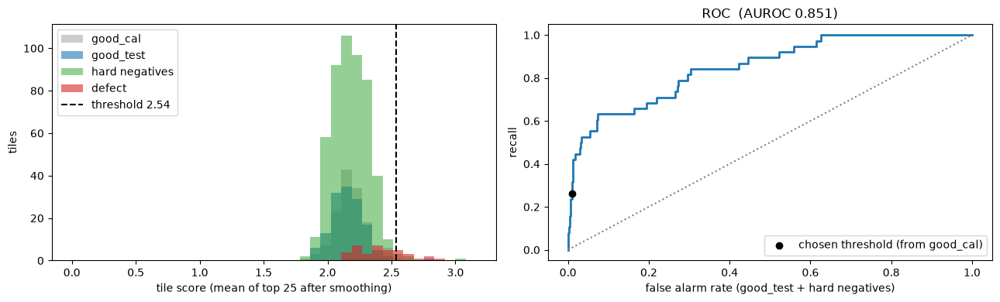

In [3]:
E.plot_scores_roc(res, S)

### Recall per defect type

In [4]:
E.print_by_type(res)

defect   tiles  found   recall  mean IoU  median area  median score
002          1      0       0%      0.06          151          2.50
006          7      1      14%      0.00         1260          2.36
019         23      7      30%      0.40           15          2.46
023          3      1      33%      0.00          778          2.29
030          4      1      25%      0.09           70          2.23


### Failure cases
Missed defects (lowest-scoring defect tiles) and false alarms (highest-scoring good_test / hard-negative tiles). Red = detected, green = ground-truth mask.

28 missed defects, 6 false alarms


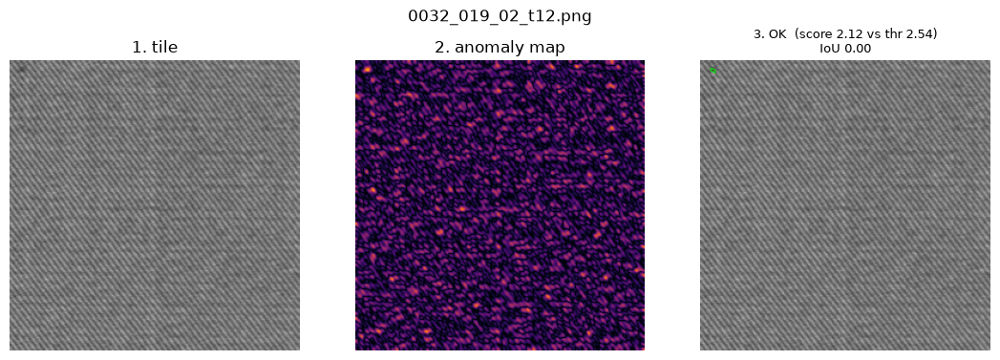

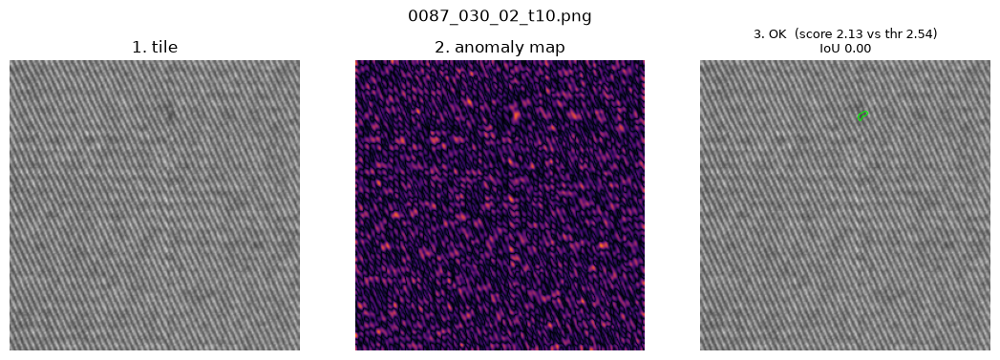

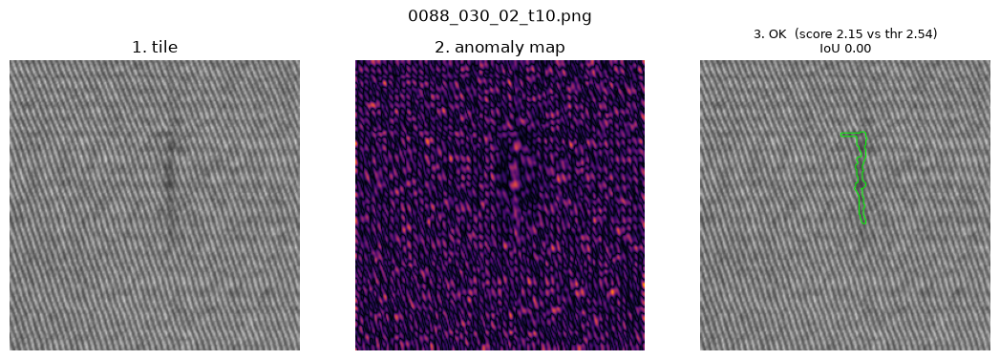

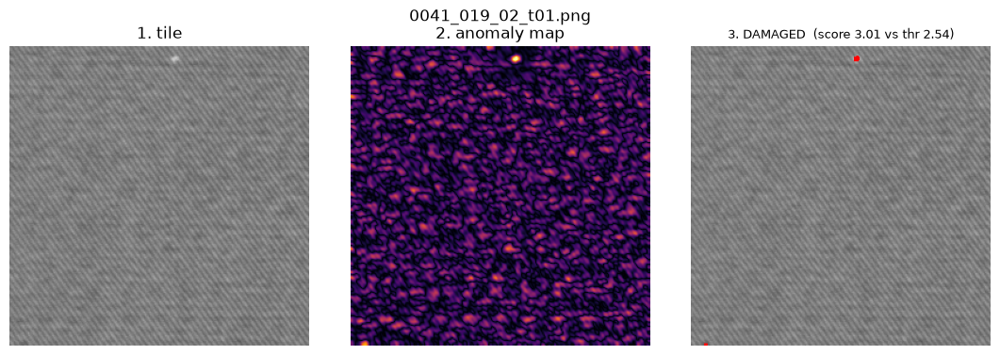

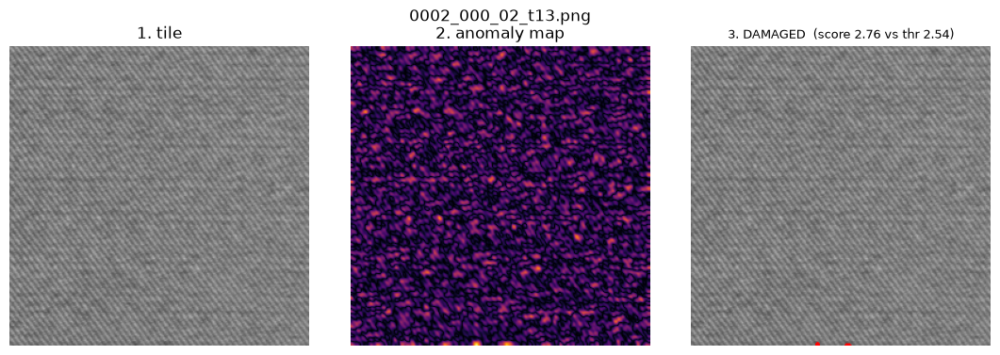

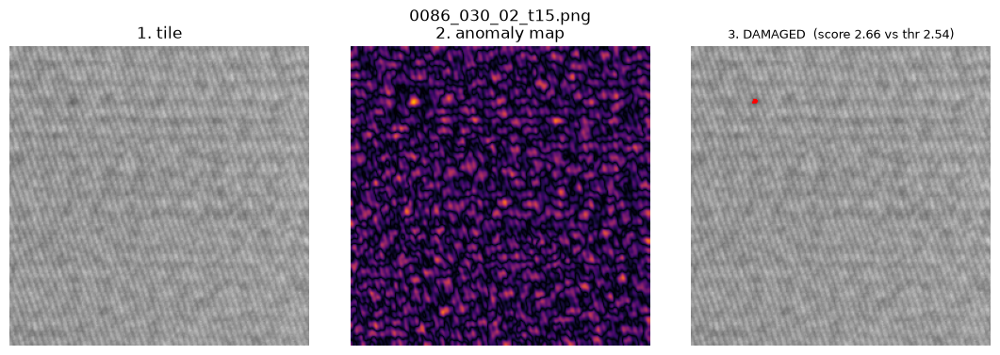

In [5]:
E.show_failures(res, n=3)

### Example tiles
Largest defect, smallest defect (by mask area) and the last good tile of `FABRIC`.

largest defect: 0016_006_02_t12.png, 2111 px


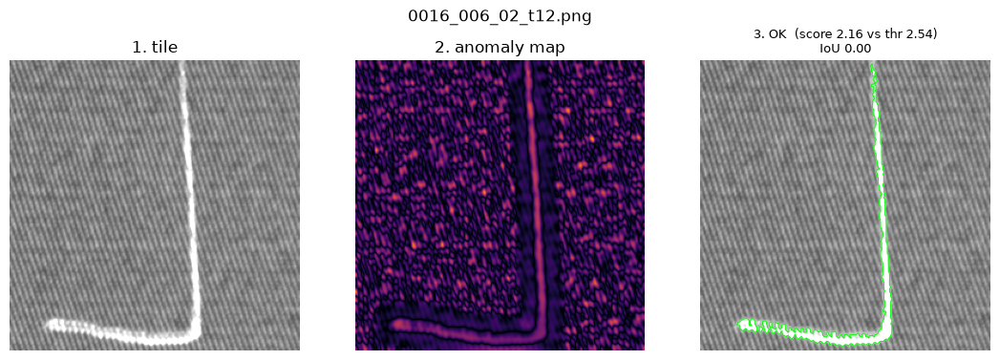

smallest defect: 0025_019_02_t10.png, 8 px


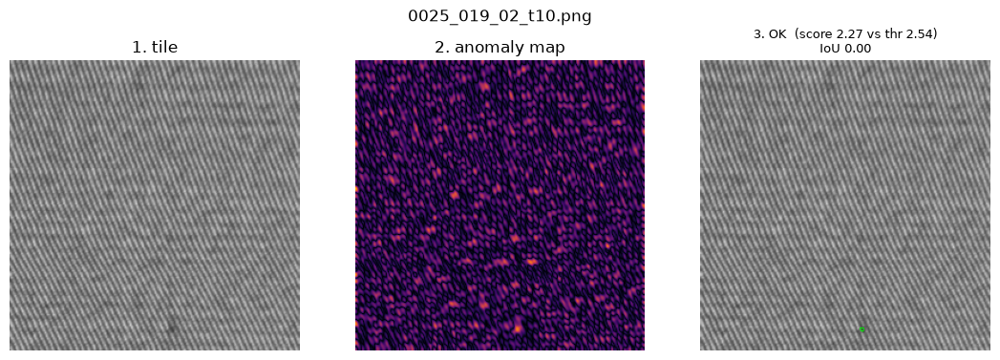

good tile: 0020_000_02_t15.png


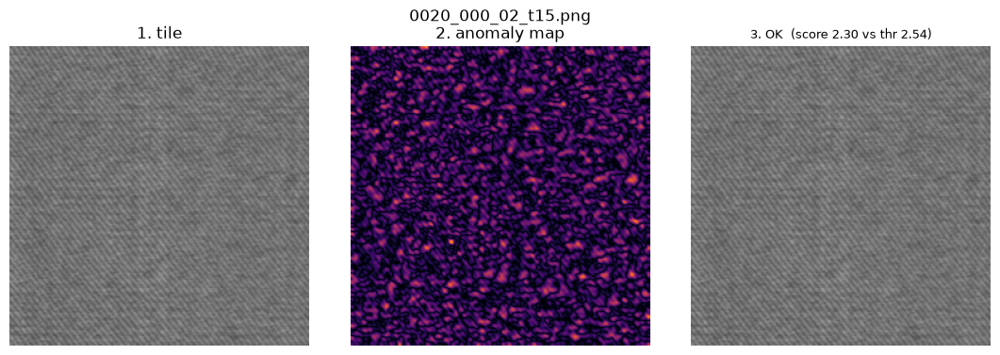

In [6]:
E.show_examples(res)

### One example per defect type
The dataset has 12 defect types (second part of the file name), spread over different fabrics. One tile per type: the clearest one (largest mask) from the fabric with the most tiles of that type. Each is judged with the threshold of its own fabric, set from that fabric's good_cal only (other fabrics are calibrated here, so this cell takes longer). Red = detected, green = ground-truth mask.

type   fabric  tiles  example tile           area px    score      thr  result
002        01     10  0005_002_01_t08.png       2514     2.17     2.45  OK (missed)
006        02      9  0016_006_02_t12.png       2111     2.16     2.54  OK (missed)
010        03     63  0103_010_03_t12.png      19060     1.57     1.79  OK (missed)
016        03      7  0021_016_03_t14.png        823     2.30     1.79  DAMAGED (caught)
019        02     40  0023_019_02_t08.png         54     2.26     2.54  OK (missed)
022        00     12  0065_022_00_t05.png        473     1.96     2.22  OK (missed)
023        01      6  0067_023_01_t09.png        577     2.07     2.45  OK (missed)
025        03      5  0107_025_03_t05.png         24     2.03     1.79  DAMAGED (caught)
027        05      1  0094_027_05_t01.png        265     2.13     2.69  OK (missed)
029        04      2  0083_029_04_t10.png        208     2.17     2.60  OK (missed)
030        03     14  0076_030_03_t09.png        222     1.87     1.79 

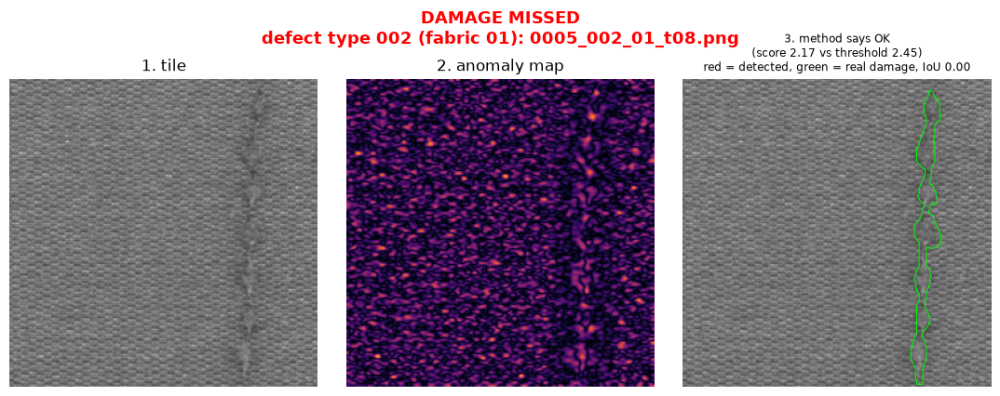

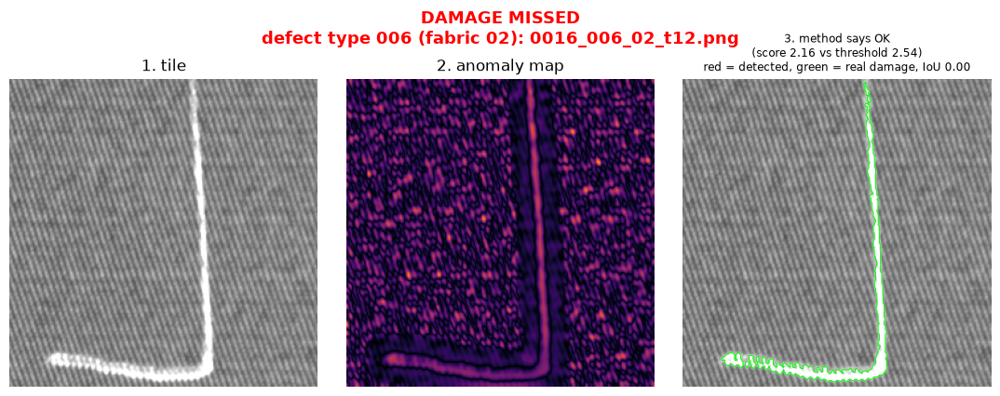

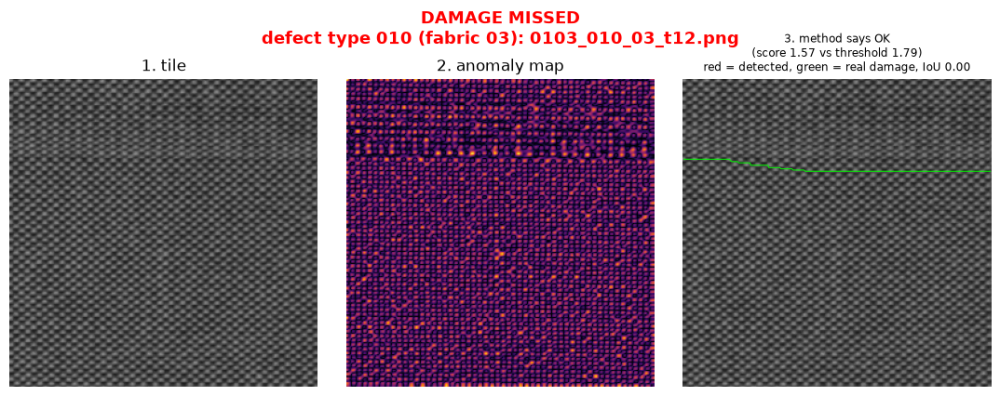

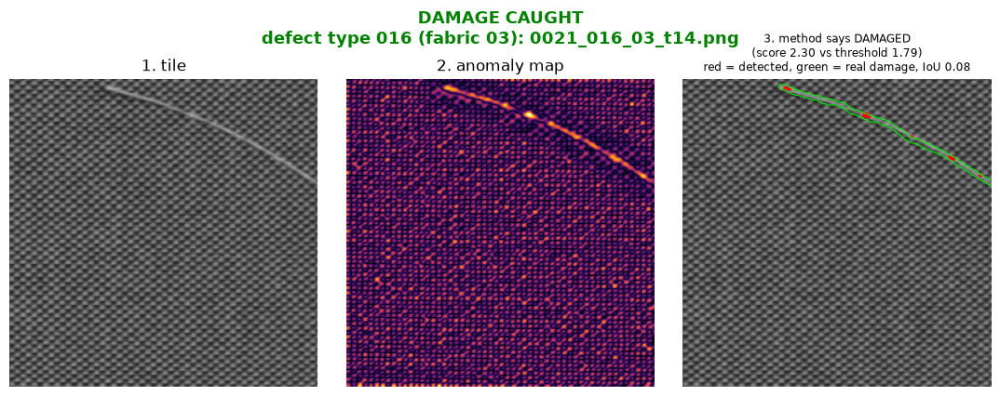

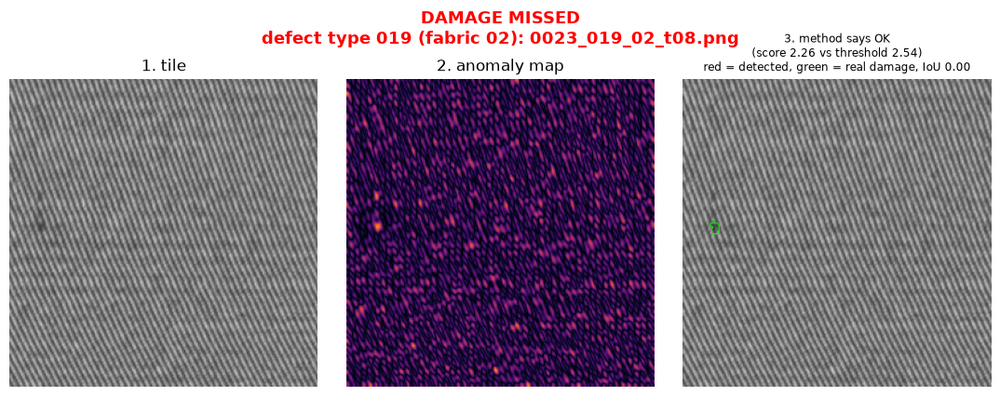

...

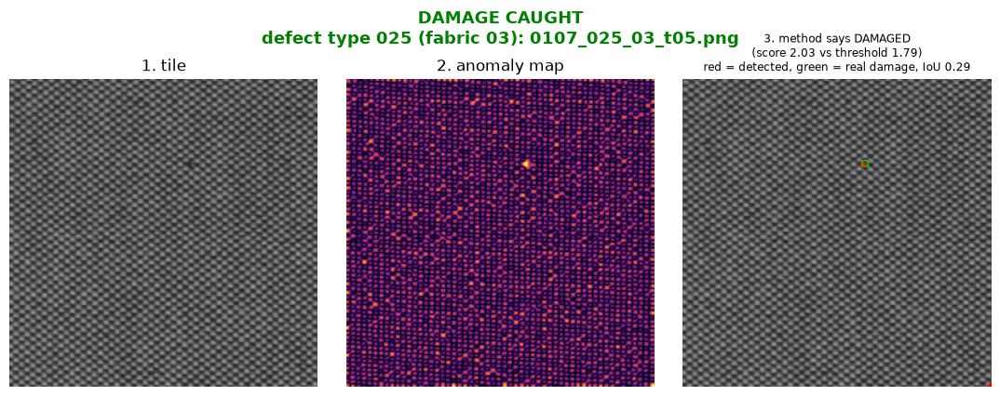

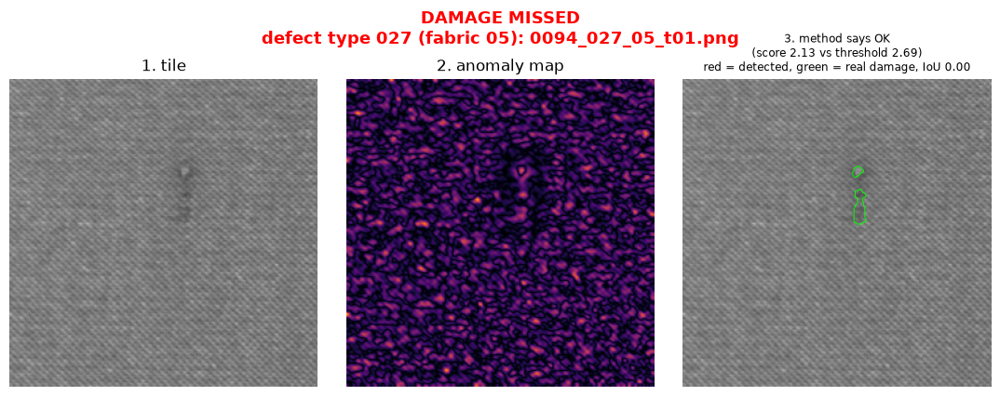

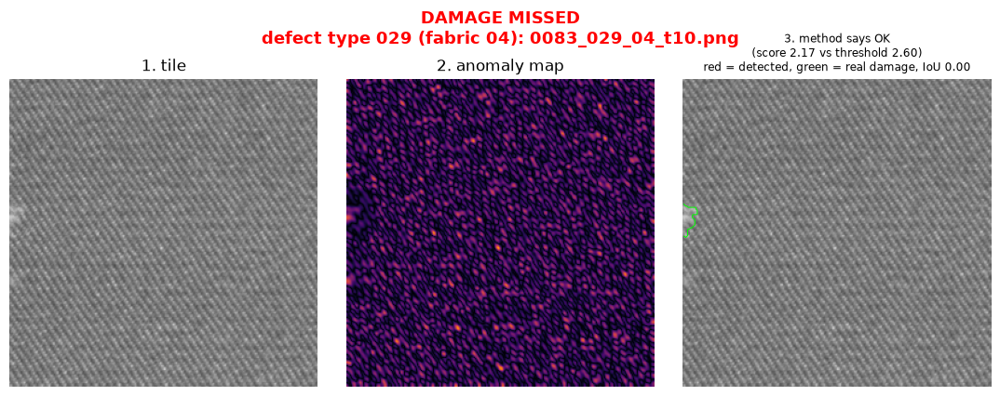

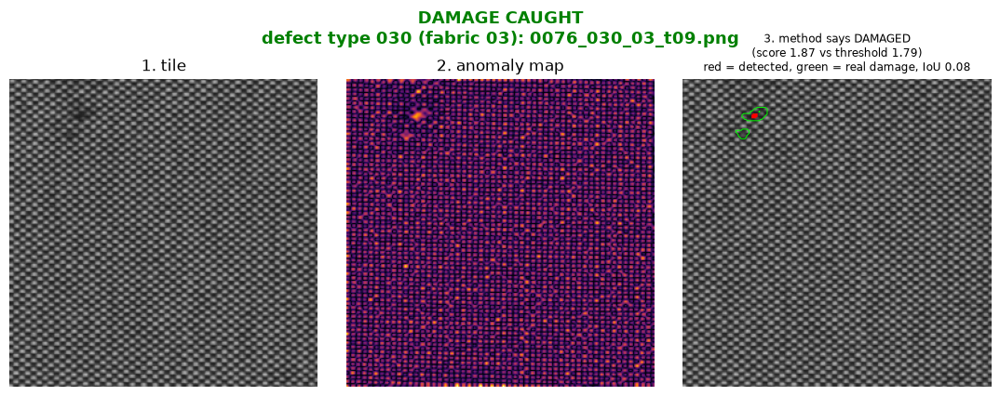

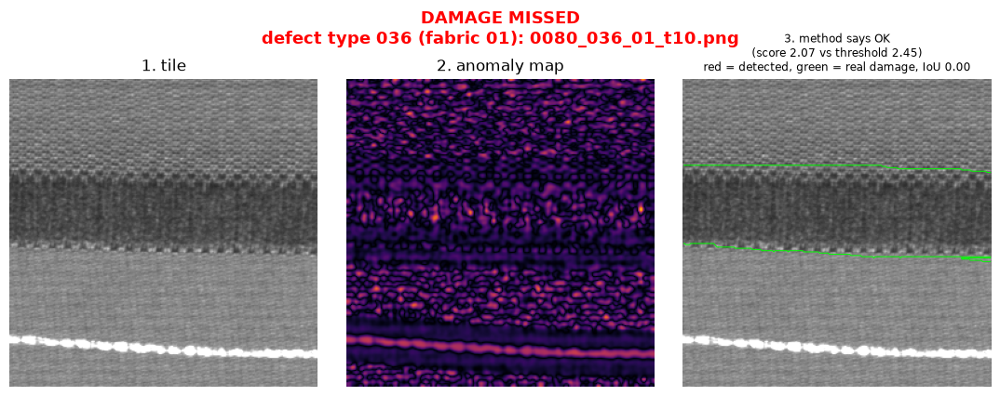

In [4]:
E.show_per_type(method, fit, res, **SETTINGS)

## All fabrics
Same method and settings on every fabric, one threshold per fabric from its own good_cal strips. Columns: FAR on good_test and on hard negatives (hn), recall overall / small / large defects, strip-level FAR and recall, AUROC, IoU, ms per tile.

In [7]:
summaries = E.all_fabrics(method, fit, METHOD_NAME, **SETTINGS)

fabric   test  hard defect    FAR  FAR hn  recall  small  large stripFAR stripRec  AUROC   IoU    ms
----------------------------------------------------------------------------------------------------
00        110    76      9   0.9%   32.9%   44.4%   0.0%  50.0%    10.0%    57.1%  0.751  0.01   0.7
01        154   146     28   0.0%    2.7%   10.7%   0.0%  11.5%     0.0%    25.0%  0.632  0.01   0.7
02        140   507     38   0.7%    1.0%   26.3%  34.8%  13.3%    10.0%    26.3%  0.851  0.25   1.0
03        110   256     89   0.0%    0.8%   30.3%  84.6%  21.1%     0.0%    70.0%  0.742  0.07   0.6
04        138   129     12   1.4%    1.6%   16.7%  40.0%   0.0%    20.0%    20.0%  0.850  0.17   0.8
05        150    13      1   0.7%    0.0%    0.0%    n/a   0.0%    10.0%     0.0%  0.288  0.00   1.0
06        143    81      7   0.7%    1.2%   42.9%  40.0%  50.0%    10.0%    50.0%  0.881  0.23   1.0
-------------------------------------------------------------------------------------------